# Exploratory Data Analysis — Student Dropout Prediction
## Real-World UCI Dataset (4,424 students from a Portuguese university)
Analyzing academic performance, demographics, socioeconomic factors, and enrollment data to understand dropout patterns.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100

## 1. Load Dataset

In [2]:
df = pd.read_csv('../data/real_student_data.csv')
print(f'Dataset Shape: {df.shape}')
print(f'\nTarget Distribution:')
print(df['Target'].value_counts())
print(f'\nColumn Types:')
print(df.dtypes.value_counts())
df.head()

Dataset Shape: (4424, 37)

Target Distribution:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Column Types:
int64      29
float64     7
object      1
Name: count, dtype: int64


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [3]:
# For binary classification: keep only Dropout and Graduate
# Remove 'Enrolled' (undecided) students
df = df[df['Target'] != 'Enrolled'].copy()
df['Dropout'] = (df['Target'] == 'Dropout').astype(int)

print(f'After removing Enrolled students: {df.shape[0]} records')
print(f'\nBinary Target Distribution:')
print(df['Dropout'].value_counts())
print(f'\nDropout Rate: {df["Dropout"].mean()*100:.1f}%')

After removing Enrolled students: 3630 records

Binary Target Distribution:
Dropout
0    2209
1    1421
Name: count, dtype: int64

Dropout Rate: 39.1%


## 2. Dataset Overview

In [4]:
print('=== Statistical Summary ===')
df.describe().round(2)

=== Statistical Summary ===


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Dropout
count,3630.00,3630.00,3630.00,3630.00,3630.00,3630.00,3630.00,3630.00,3630.00,3630.00,...,3630.00,3630.00,3630.00,3630.00,3630.00,3630.00,3630.00,3630.00,3630.00,3630.00
mean,1.18,18.42,1.75,8853.98,0.89,4.53,132.92,1.83,19.99,22.57,...,0.58,6.30,7.76,4.52,10.04,0.14,11.63,1.23,-0.01,0.39
std,0.61,17.36,1.33,2068.76,0.32,10.02,13.24,6.67,15.59,15.28,...,2.02,2.26,3.96,3.16,5.48,0.75,2.67,1.38,2.26,0.49
min,1.00,1.00,0.00,33.00,0.00,1.00,95.00,1.00,1.00,1.00,...,0.00,0.00,0.00,0.00,0.00,0.00,7.60,-0.80,-4.06,0.00
25%,1.00,1.00,1.00,9085.00,1.00,1.00,125.00,1.00,2.00,3.00,...,0.00,5.00,6.00,2.00,10.52,0.00,9.40,0.30,-1.70,0.00
50%,1.00,17.00,1.00,9254.00,1.00,1.00,133.10,1.00,19.00,19.00,...,0.00,6.00,8.00,5.00,12.33,0.00,11.10,1.40,0.32,0.00
75%,1.00,39.00,2.00,9556.00,1.00,1.00,140.00,1.00,37.00,37.00,...,0.00,7.00,10.00,6.00,13.50,0.00,13.90,2.60,1.79,1.00
max,6.00,57.00,6.00,9991.00,1.00,43.00,190.00,109.00,44.00,44.00,...,19.00,23.00,33.00,20.00,18.57,12.00,16.20,3.70,3.51,1.00


In [5]:
print('=== Missing Values ===')
missing = df.isnull().sum()
total_missing = missing.sum()
print(f'Total missing values: {total_missing}')
if total_missing > 0:
    missing_pct = (missing / len(df) * 100).round(2)
    print(pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct}).query('`Missing Count` > 0'))
else:
    print('No missing values in the dataset!')

=== Missing Values ===
Total missing values: 0
No missing values in the dataset!


## 3. Target Variable Distribution (Dropout)

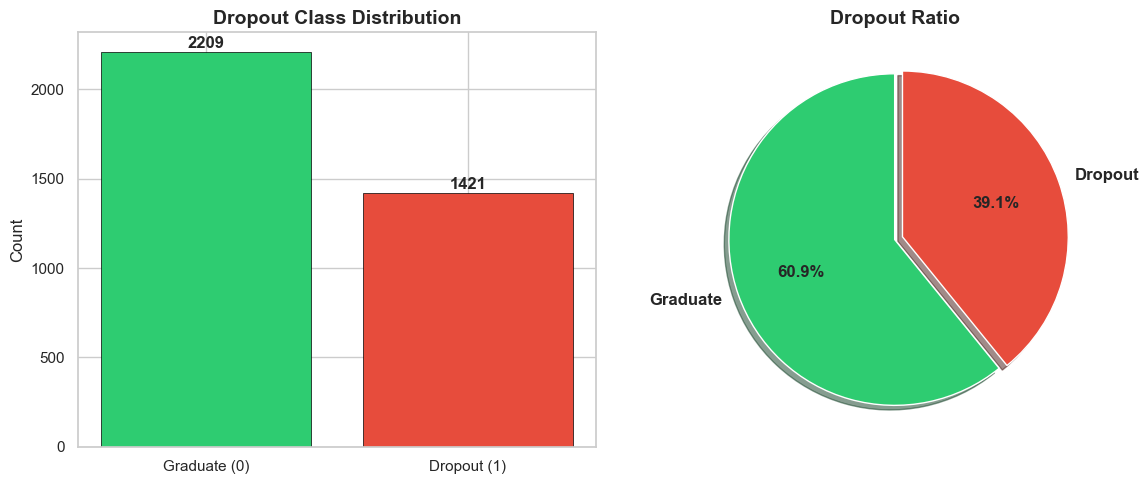

Dropout Rate: 39.1% (imbalanced dataset)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

dropout_counts = df['Dropout'].value_counts().sort_index()
colors = ['#2ecc71', '#e74c3c']
axes[0].bar(['Graduate (0)', 'Dropout (1)'], dropout_counts.values, color=colors,
            edgecolor='black', linewidth=0.5)
axes[0].set_title('Dropout Class Distribution', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(dropout_counts.values):
    axes[0].text(i, v + 20, str(v), ha='center', fontweight='bold', fontsize=12)

axes[1].pie(dropout_counts.values, labels=['Graduate', 'Dropout'], autopct='%1.1f%%',
            colors=colors, startangle=90, explode=(0, 0.05), shadow=True,
            textprops={'fontsize': 12, 'fontweight': 'bold'})
axes[1].set_title('Dropout Ratio', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('../data/dropout_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Dropout Rate: {df["Dropout"].mean()*100:.1f}% (imbalanced dataset)')

## 4. Feature Distributions — Academic Performance

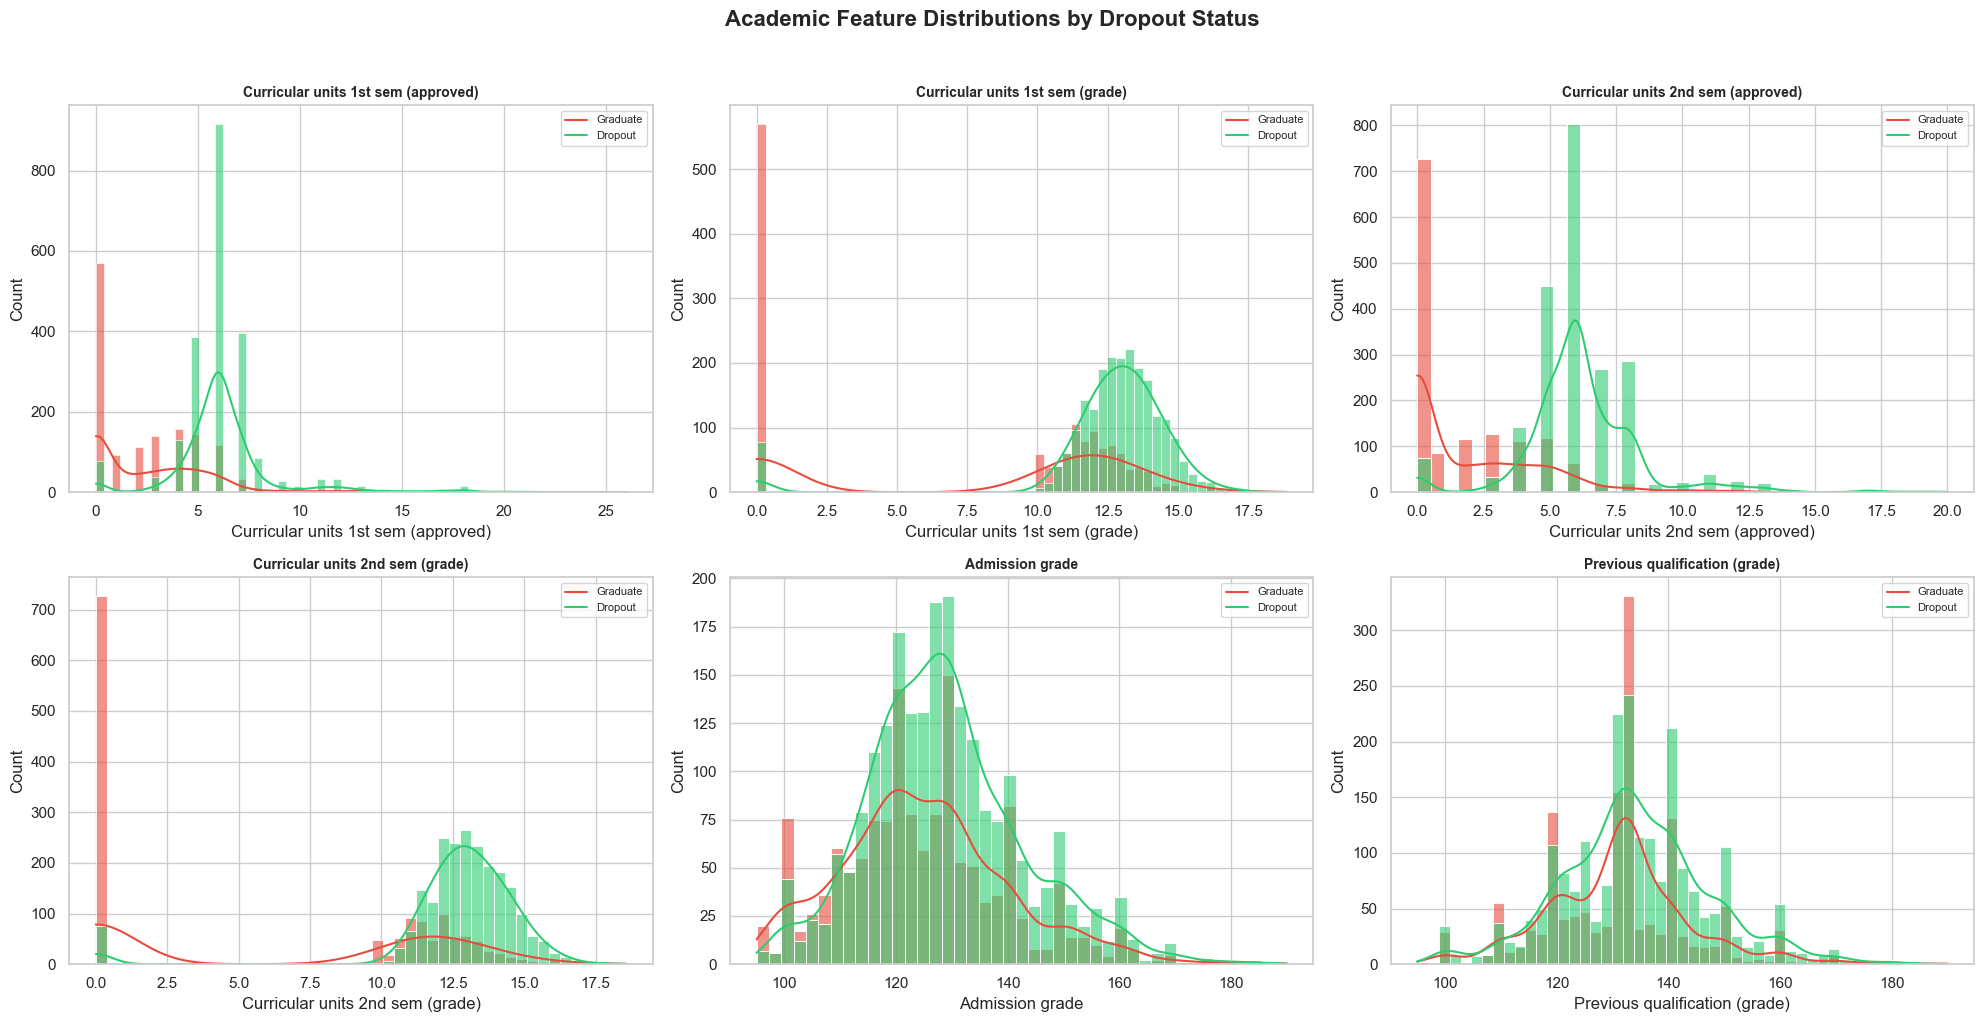

In [7]:
academic_cols = [
    'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)',
    'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)',
    'Admission grade', 'Previous qualification (grade)'
]

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
axes = axes.flatten()

for i, col in enumerate(academic_cols):
    sns.histplot(data=df, x=col, hue='Dropout', kde=True, ax=axes[i],
                 palette=['#2ecc71', '#e74c3c'], alpha=0.6)
    axes[i].set_title(col, fontsize=10, fontweight='bold')
    axes[i].legend(['Graduate', 'Dropout'], fontsize=8)

plt.suptitle('Academic Feature Distributions by Dropout Status', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../data/feature_distributions_academic.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Feature Distributions — Socioeconomic & Demographic

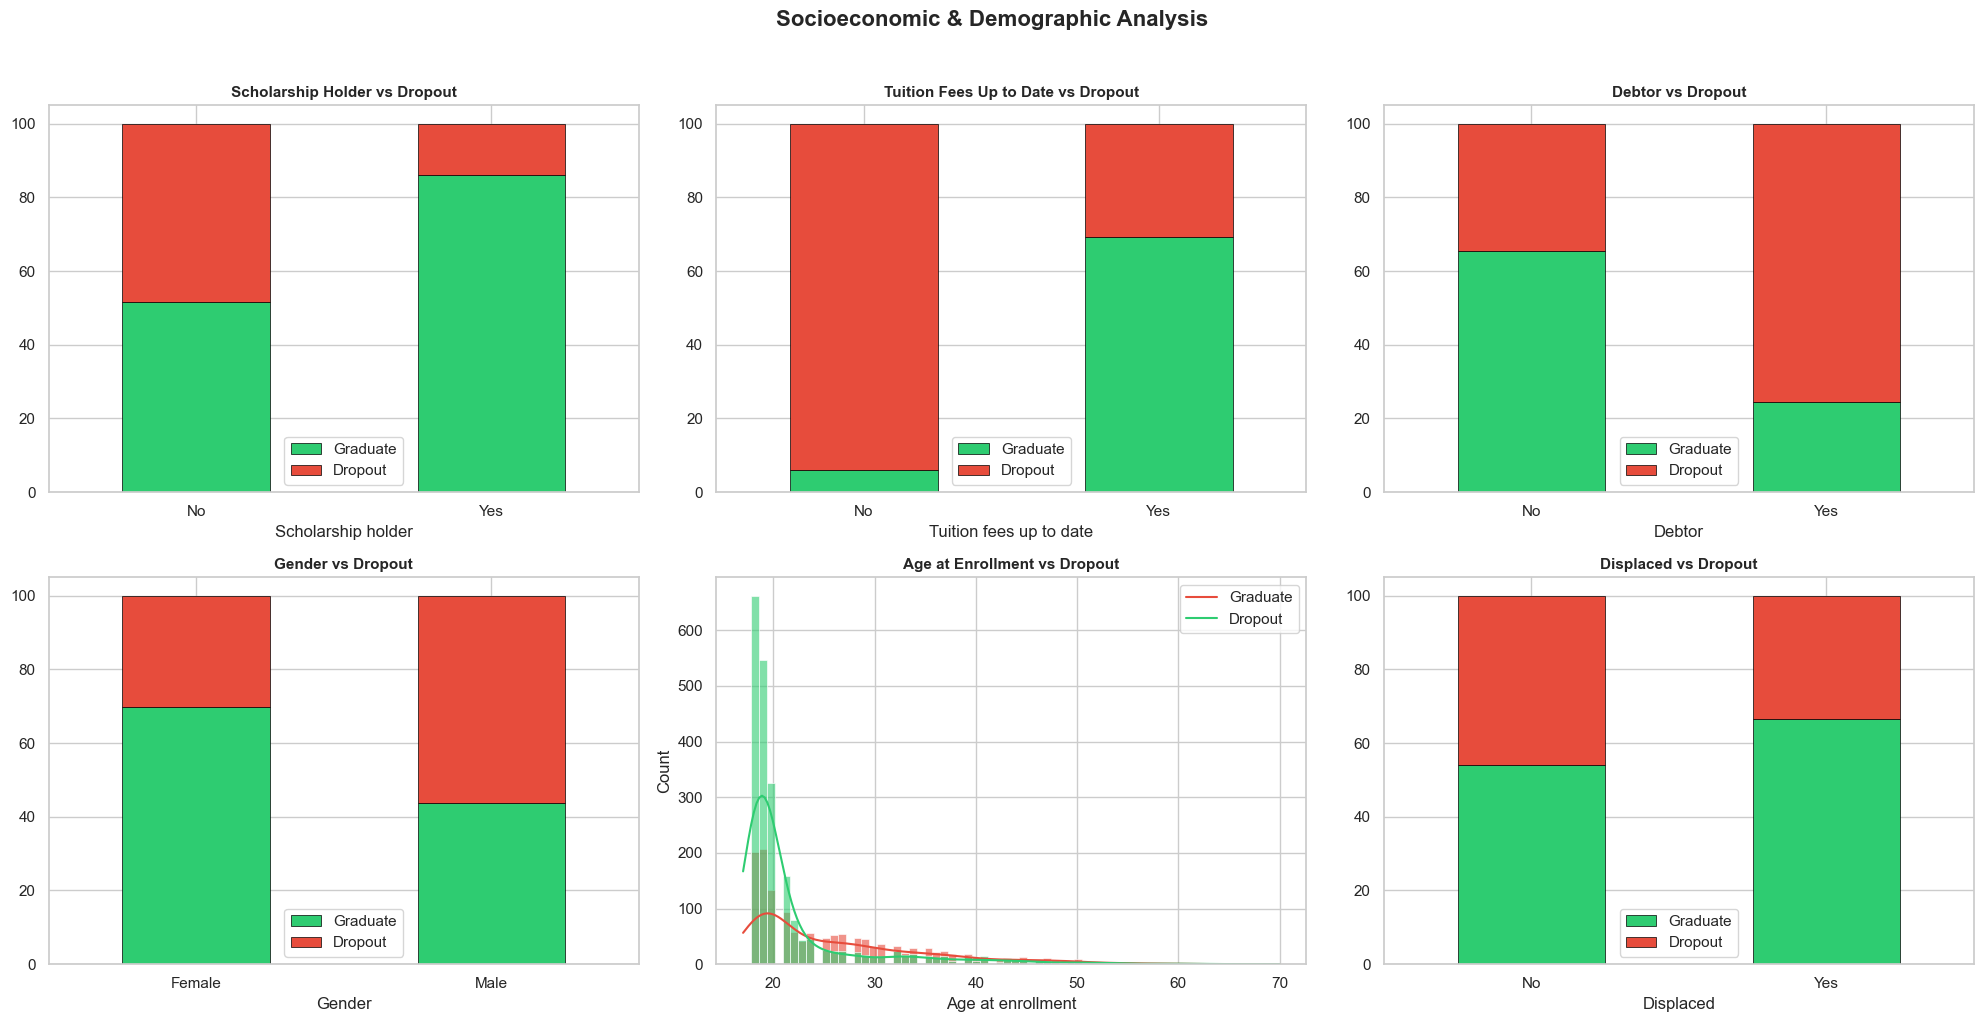

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))

# Scholarship vs Dropout
ct = pd.crosstab(df['Scholarship holder'], df['Dropout'], normalize='index') * 100
ct.plot(kind='bar', stacked=True, color=['#2ecc71', '#e74c3c'], ax=axes[0, 0],
        edgecolor='black', linewidth=0.5)
axes[0, 0].set_title('Scholarship Holder vs Dropout', fontsize=11, fontweight='bold')
axes[0, 0].set_xticklabels(['No', 'Yes'], rotation=0)
axes[0, 0].legend(['Graduate', 'Dropout'])

# Tuition Fees vs Dropout
ct2 = pd.crosstab(df['Tuition fees up to date'], df['Dropout'], normalize='index') * 100
ct2.plot(kind='bar', stacked=True, color=['#2ecc71', '#e74c3c'], ax=axes[0, 1],
         edgecolor='black', linewidth=0.5)
axes[0, 1].set_title('Tuition Fees Up to Date vs Dropout', fontsize=11, fontweight='bold')
axes[0, 1].set_xticklabels(['No', 'Yes'], rotation=0)
axes[0, 1].legend(['Graduate', 'Dropout'])

# Debtor vs Dropout
ct3 = pd.crosstab(df['Debtor'], df['Dropout'], normalize='index') * 100
ct3.plot(kind='bar', stacked=True, color=['#2ecc71', '#e74c3c'], ax=axes[0, 2],
         edgecolor='black', linewidth=0.5)
axes[0, 2].set_title('Debtor vs Dropout', fontsize=11, fontweight='bold')
axes[0, 2].set_xticklabels(['No', 'Yes'], rotation=0)
axes[0, 2].legend(['Graduate', 'Dropout'])

# Gender vs Dropout
ct4 = pd.crosstab(df['Gender'], df['Dropout'], normalize='index') * 100
ct4.plot(kind='bar', stacked=True, color=['#2ecc71', '#e74c3c'], ax=axes[1, 0],
         edgecolor='black', linewidth=0.5)
axes[1, 0].set_title('Gender vs Dropout', fontsize=11, fontweight='bold')
axes[1, 0].set_xticklabels(['Female', 'Male'], rotation=0)
axes[1, 0].legend(['Graduate', 'Dropout'])

# Age Distribution
sns.histplot(data=df, x='Age at enrollment', hue='Dropout', kde=True, ax=axes[1, 1],
             palette=['#2ecc71', '#e74c3c'], alpha=0.6)
axes[1, 1].set_title('Age at Enrollment vs Dropout', fontsize=11, fontweight='bold')
axes[1, 1].legend(['Graduate', 'Dropout'])

# Displaced vs Dropout
ct5 = pd.crosstab(df['Displaced'], df['Dropout'], normalize='index') * 100
ct5.plot(kind='bar', stacked=True, color=['#2ecc71', '#e74c3c'], ax=axes[1, 2],
         edgecolor='black', linewidth=0.5)
axes[1, 2].set_title('Displaced vs Dropout', fontsize=11, fontweight='bold')
axes[1, 2].set_xticklabels(['No', 'Yes'], rotation=0)
axes[1, 2].legend(['Graduate', 'Dropout'])

plt.suptitle('Socioeconomic & Demographic Analysis', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../data/feature_distributions_socioeconomic.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Correlation Heatmap

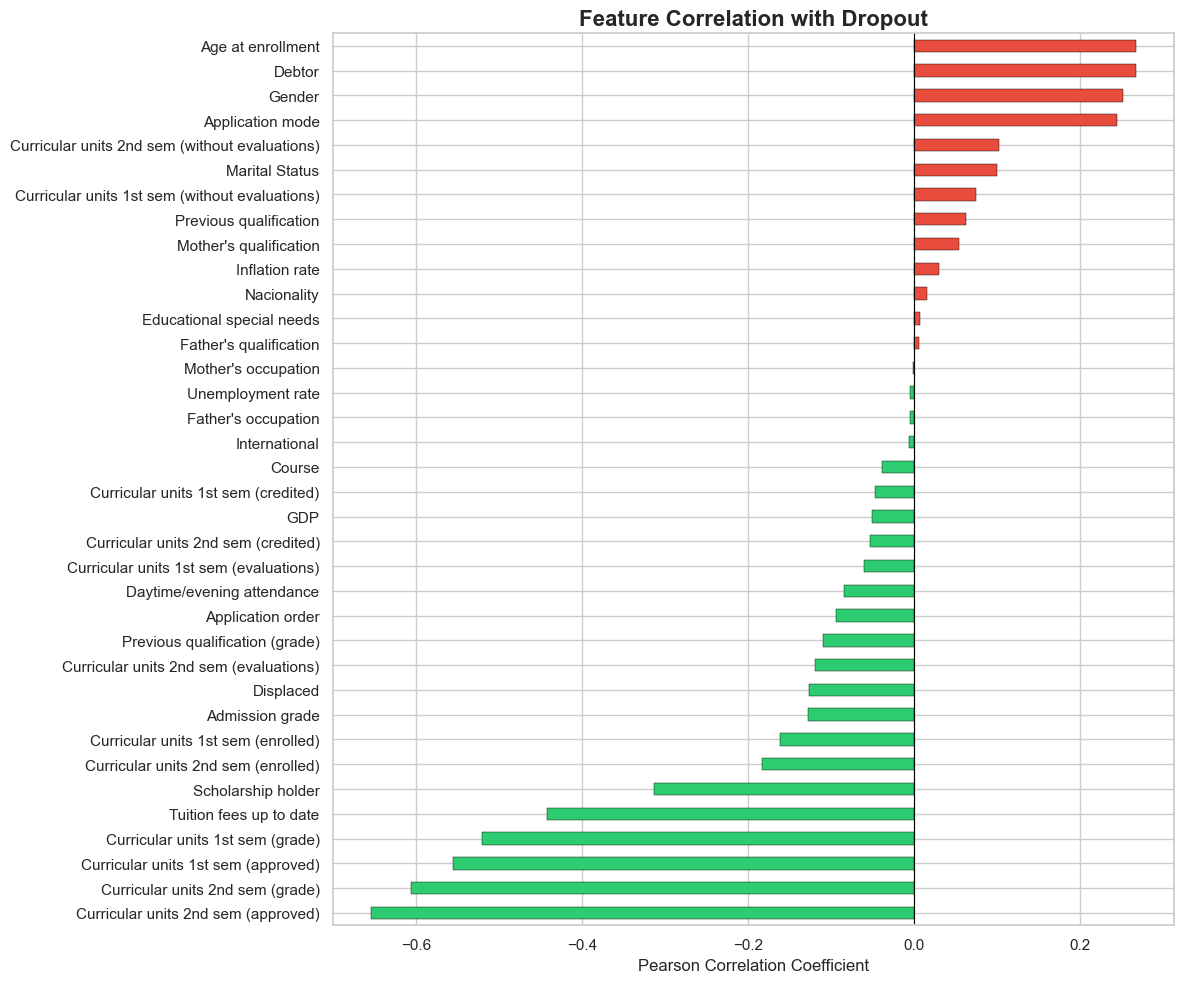


=== Top 10 Positive Correlators (RISK factors) ===
Inflation rate                                    0.030
Mother's qualification                            0.054
Previous qualification                            0.062
Curricular units 1st sem (without evaluations)    0.075
Marital Status                                    0.100
Curricular units 2nd sem (without evaluations)    0.103
Application mode                                  0.245
Gender                                            0.252
Debtor                                            0.267
Age at enrollment                                 0.267

=== Top 10 Negative Correlators (PROTECTIVE factors) ===
Curricular units 2nd sem (approved)   -0.654
Curricular units 2nd sem (grade)      -0.605
Curricular units 1st sem (approved)   -0.555
Curricular units 1st sem (grade)      -0.520
Tuition fees up to date               -0.442
Scholarship holder                    -0.313
Curricular units 2nd sem (enrolled)   -0.183
Curricular unit

In [9]:
numeric_df = df.select_dtypes(include=[np.number]).drop(columns=['Dropout'], errors='ignore')
corr_with_dropout = numeric_df.corrwith(df['Dropout']).sort_values()

plt.figure(figsize=(12, 10))
colors = ['#e74c3c' if v > 0 else '#2ecc71' for v in corr_with_dropout.values]
corr_with_dropout.plot(kind='barh', color=colors, edgecolor='black', linewidth=0.3)
plt.title('Feature Correlation with Dropout', fontsize=16, fontweight='bold')
plt.xlabel('Pearson Correlation Coefficient')
plt.axvline(x=0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig('../data/correlation_with_dropout.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n=== Top 10 Positive Correlators (RISK factors) ===')
print(corr_with_dropout.tail(10).round(3).to_string())
print('\n=== Top 10 Negative Correlators (PROTECTIVE factors) ===')
print(corr_with_dropout.head(10).round(3).to_string())

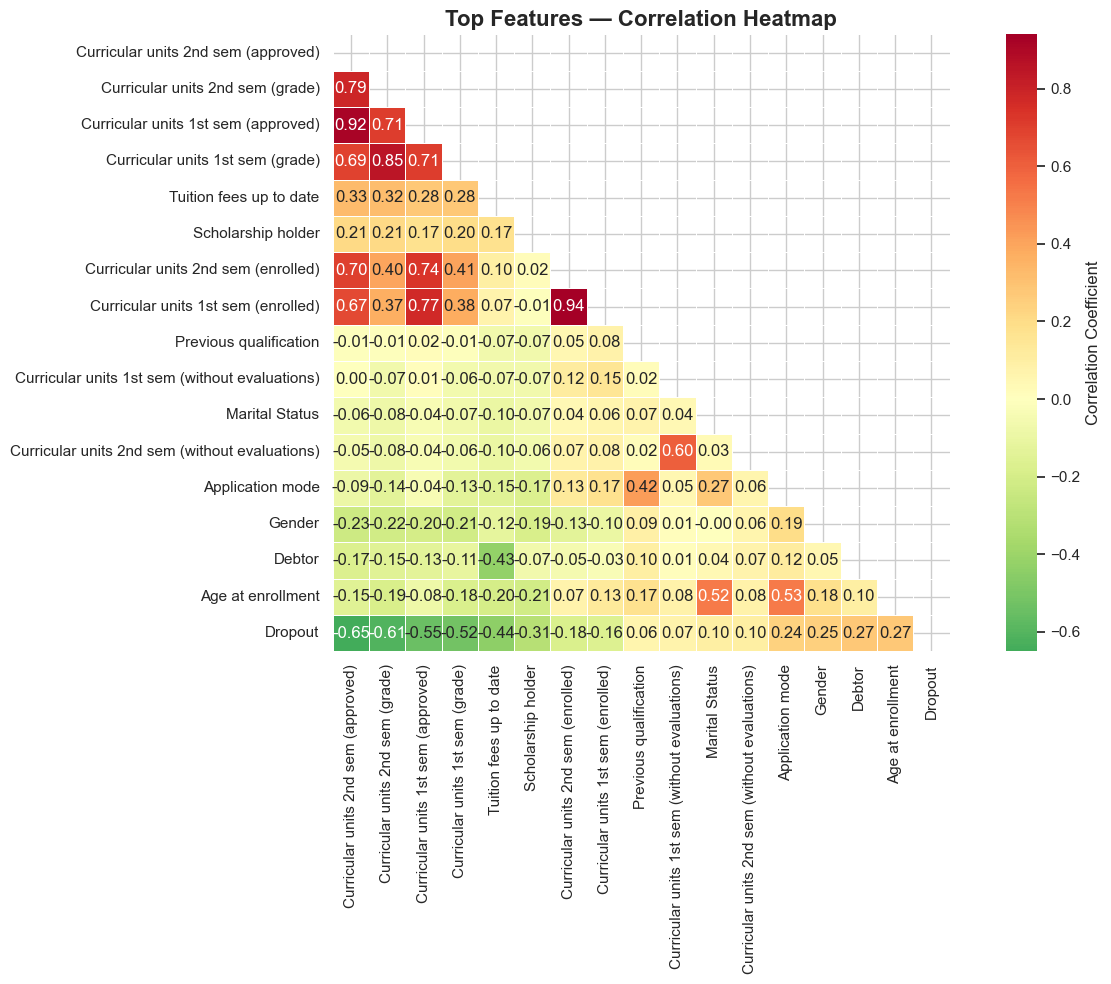

In [10]:
# Top features heatmap
top_features = list(corr_with_dropout.head(8).index) + list(corr_with_dropout.tail(8).index) + ['Dropout']
top_features = [f for f in top_features if f in df.columns]

corr_matrix = df[top_features].corr().round(2)

plt.figure(figsize=(14, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='RdYlGn_r', center=0,
            fmt='.2f', square=True, linewidths=0.5,
            cbar_kws={'label': 'Correlation Coefficient'})
plt.title('Top Features — Correlation Heatmap', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Box Plots — Dropout vs Key Features

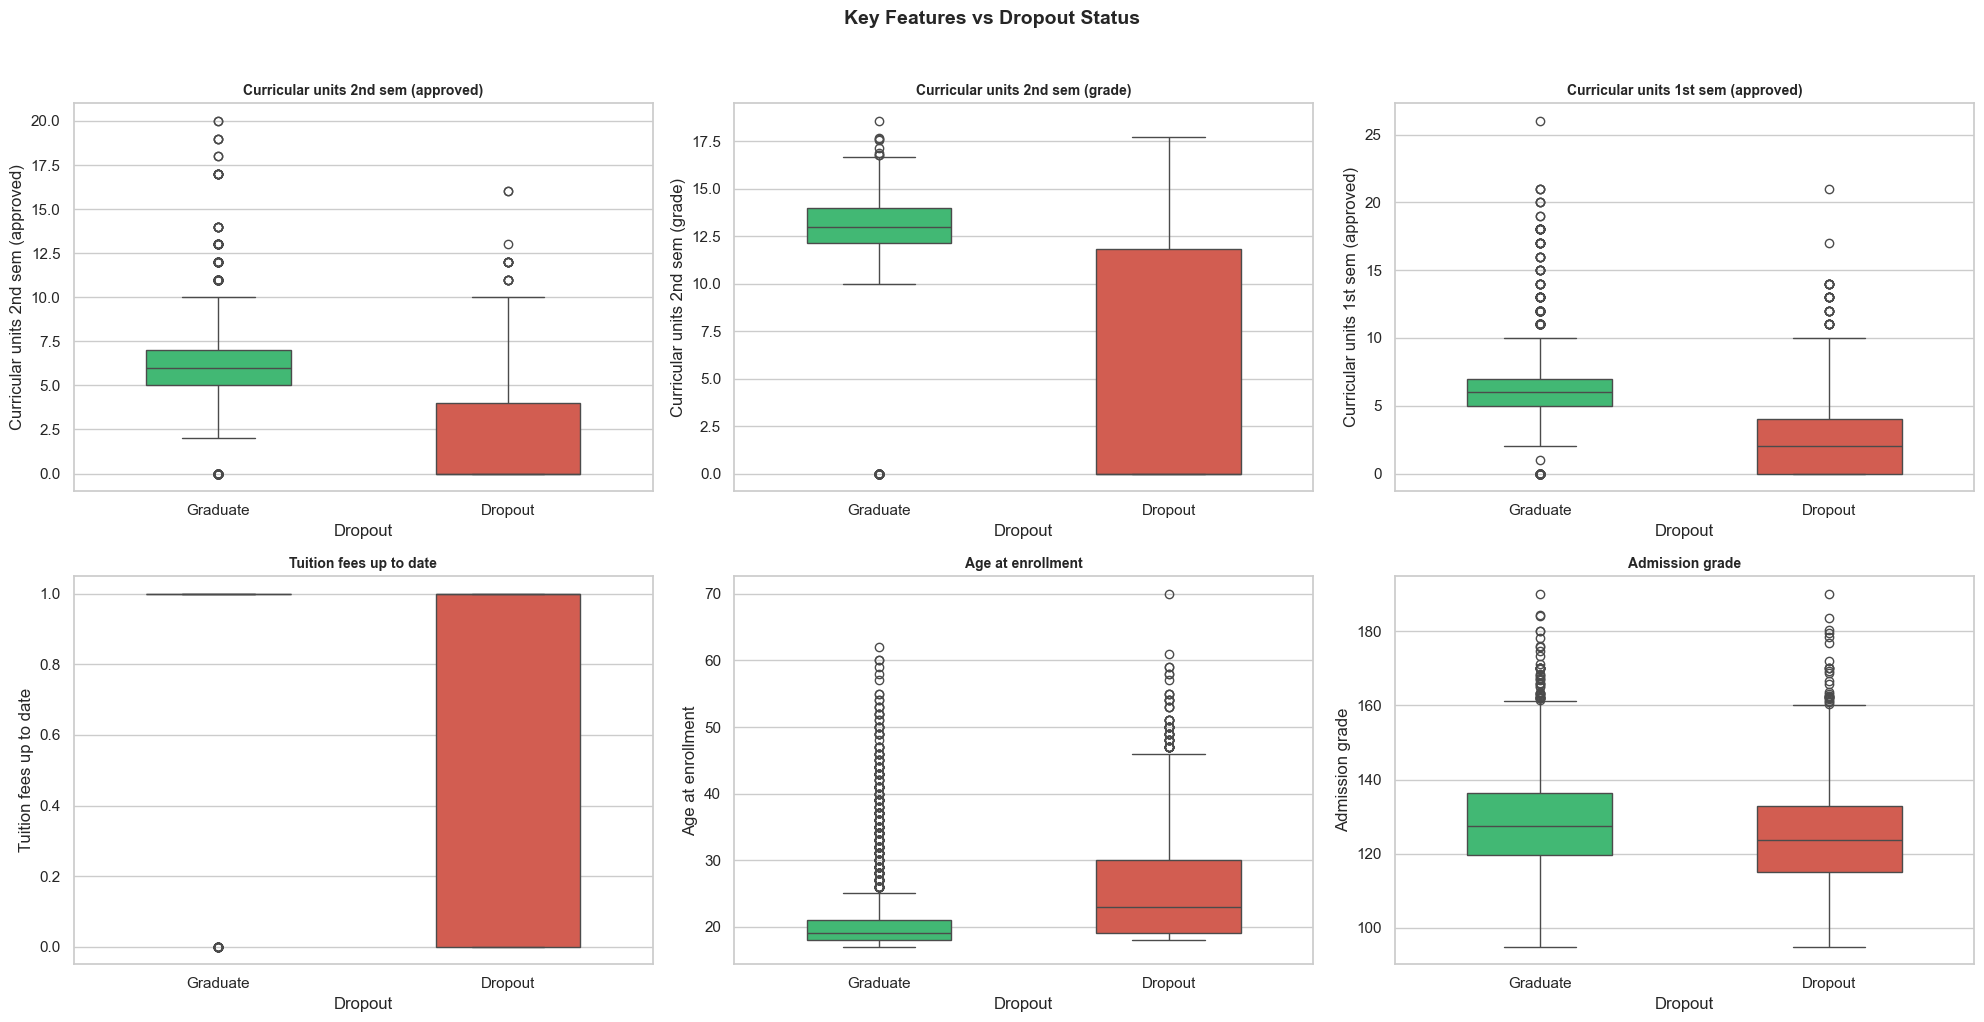

In [11]:
key_features = [
    'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)',
    'Curricular units 1st sem (approved)', 'Tuition fees up to date',
    'Age at enrollment', 'Admission grade'
]

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
axes = axes.flatten()

for i, col in enumerate(key_features):
    sns.boxplot(data=df, x='Dropout', y=col, ax=axes[i],
                hue='Dropout', palette=['#2ecc71', '#e74c3c'], width=0.5, legend=False)
    axes[i].set_title(f'{col}', fontsize=10, fontweight='bold')
    axes[i].set_xticklabels(['Graduate', 'Dropout'])

plt.suptitle('Key Features vs Dropout Status', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../data/boxplots_dropout.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Macroeconomic Factors

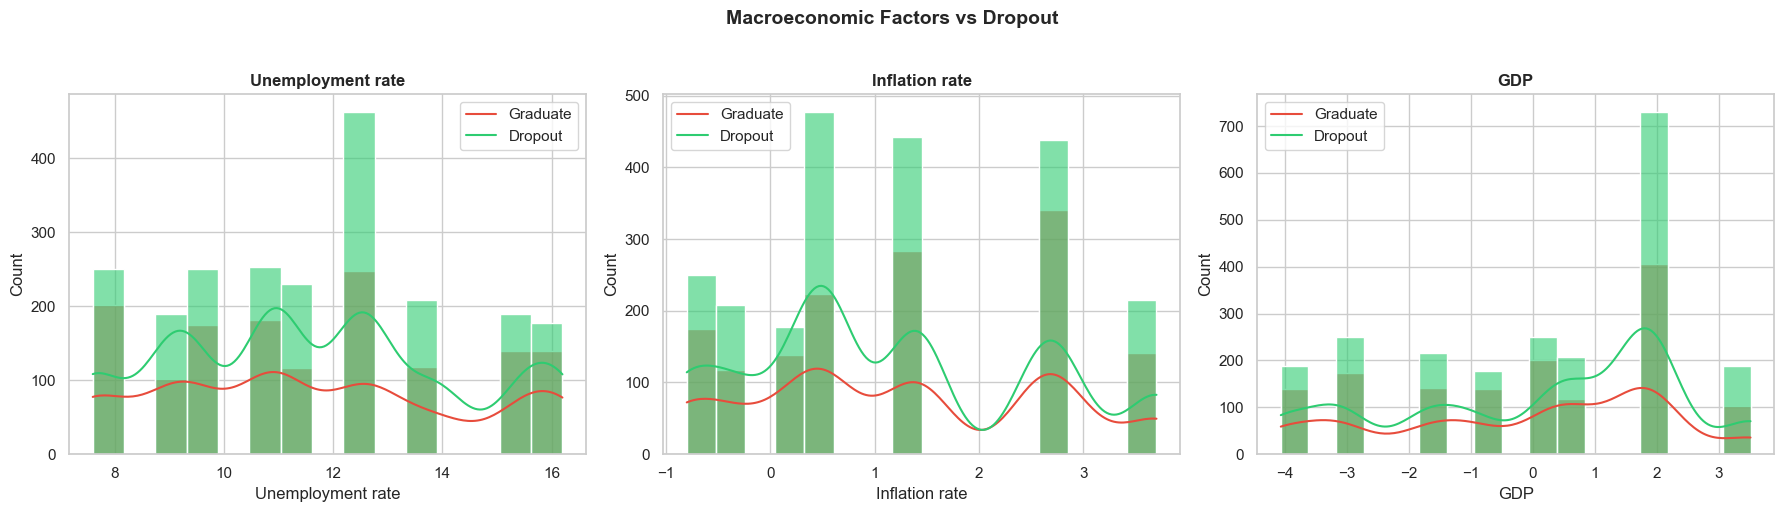

In [12]:
macro_cols = ['Unemployment rate', 'Inflation rate', 'GDP']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(macro_cols):
    sns.histplot(data=df, x=col, hue='Dropout', kde=True, ax=axes[i],
                 palette=['#2ecc71', '#e74c3c'], alpha=0.6)
    axes[i].set_title(col, fontsize=12, fontweight='bold')
    axes[i].legend(['Graduate', 'Dropout'])

plt.suptitle('Macroeconomic Factors vs Dropout', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../data/macroeconomic_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Key Insights Summary

In [13]:
print('=' * 65)
print('         EDA KEY INSIGHTS — REAL-WORLD UCI DATASET')
print('=' * 65)

print(f'\n1. DATASET: {len(df)} students (after removing Enrolled), 37 features')
print(f'   Source: Portuguese university (UCI ML Repository #697)')
print(f'2. DROPOUT RATE: {df["Dropout"].mean()*100:.1f}% (IMBALANCED - needs handling)')
print(f'3. MISSING VALUES: 0 (clean dataset)')

print(f'\n4. STRONGEST PROTECTIVE FACTORS (reduce dropout):')
for feat, val in corr_with_dropout.head(5).items():
    print(f'   {feat}: {val:.3f}')

print(f'\n5. STRONGEST RISK FACTORS (increase dropout):')
for feat, val in corr_with_dropout.tail(5).items():
    print(f'   {feat}: {val:.3f}')

print(f'\n6. KEY OBSERVATIONS:')
print(f'   - Students who approve more curricular units are far less likely to drop out')
print(f'   - Tuition fee payment is a strong indicator: unpaid fees correlate with dropout')
print(f'   - Older students at enrollment have higher dropout rates')
print(f'   - Scholarship holders have lower dropout rates')
print(f'   - Debtors are significantly more likely to drop out')

# Financial impact
debt_dropout = df[df['Debtor']==1]['Dropout'].mean()*100
no_debt_dropout = df[df['Debtor']==0]['Dropout'].mean()*100
tuition_paid_dropout = df[df['Tuition fees up to date']==1]['Dropout'].mean()*100
tuition_unpaid_dropout = df[df['Tuition fees up to date']==0]['Dropout'].mean()*100

print(f'\n7. FINANCIAL IMPACT:')
print(f'   Debtors: {debt_dropout:.1f}% dropout vs Non-debtors: {no_debt_dropout:.1f}%')
print(f'   Tuition unpaid: {tuition_unpaid_dropout:.1f}% dropout vs Paid: {tuition_paid_dropout:.1f}%')

print('\n' + '=' * 65)
print('CONCLUSION: Curricular unit performance (1st & 2nd semester)')
print('and financial factors (tuition, debt) are the strongest')
print('predictors. The dataset is imbalanced (39% dropout) and')
print('will need SMOTE or class weights during model training.')
print('=' * 65)

         EDA KEY INSIGHTS — REAL-WORLD UCI DATASET

1. DATASET: 3630 students (after removing Enrolled), 37 features
   Source: Portuguese university (UCI ML Repository #697)
2. DROPOUT RATE: 39.1% (IMBALANCED - needs handling)
3. MISSING VALUES: 0 (clean dataset)

4. STRONGEST PROTECTIVE FACTORS (reduce dropout):
   Curricular units 2nd sem (approved): -0.654
   Curricular units 2nd sem (grade): -0.605
   Curricular units 1st sem (approved): -0.555
   Curricular units 1st sem (grade): -0.520
   Tuition fees up to date: -0.442

5. STRONGEST RISK FACTORS (increase dropout):
   Curricular units 2nd sem (without evaluations): 0.103
   Application mode: 0.245
   Gender: 0.252
   Debtor: 0.267
   Age at enrollment: 0.267

6. KEY OBSERVATIONS:
   - Students who approve more curricular units are far less likely to drop out
   - Tuition fee payment is a strong indicator: unpaid fees correlate with dropout
   - Older students at enrollment have higher dropout rates
   - Scholarship holders have